In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from datetime import timedelta

import warnings
warnings.filterwarnings("ignore")

# Statistical / ML
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Display
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
import pandas as pd

# Google Drive file ID
FILE_ID = "1qP9Tu74ZN--XyBit6bBptk-Lfiliu_fy"

# Direct download URL
FILE_URL = f"https://drive.google.com/uc?export=download&id={FILE_ID}"

# Load dataset
df = pd.read_csv(FILE_URL)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset loaded successfully!
Dataset Shape: (261538, 4)

Column Names:
['_id', 'Timestamp', 'Redemption Count', 'Sales Count']

First 5 Records:


,_id,Timestamp,Redemption Count,Sales Count
0,1,2025-12-21T22:30:00,14,16
1,2,2025-12-21T22:15:00,1,0
2,3,2025-12-21T22:00:00,2,0
3,4,2025-12-21T21:30:00,11,1
4,5,2025-12-21T21:15:00,10,0


In [3]:
# Dataset information
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Columns:
['_id', 'Timestamp', 'Redemption Count', 'Sales Count']

Data Types:
_id                  int64
Timestamp           object
Redemption Count     int64
Sales Count          int64
dtype: object

Dataset Shape:
(261538, 4)

Missing Values:


,Missing Values
_id,0
Timestamp,0
Redemption Count,0
Sales Count,0



Duplicate Rows:
0


In [4]:
# ============================================================
# STANDARDIZE COLUMN NAMES
# ============================================================

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['_id', 'timestamp', 'redemption_count', 'sales_count']


In [5]:
# ============================================================
# REQUIRED COLUMN VALIDATION
# ============================================================

required_columns = [
    "timestamp",
    "sales_count",
    "redemption_count"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required columns are present.")

All required columns are present.


In [6]:
# ============================================================
# DATA TYPE CONVERSION
# ============================================================

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df["sales_count"] = pd.to_numeric(
    df["sales_count"],
    errors="coerce"
)

df["redemption_count"] = pd.to_numeric(
    df["redemption_count"],
    errors="coerce"
)

print(df.dtypes)

_id                          int64
timestamp           datetime64[ns]
redemption_count             int64
sales_count                  int64
dtype: object


In [7]:
invalid_timestamps = df["timestamp"].isna().sum()

print("Invalid timestamps:", invalid_timestamps)

df = df.dropna(
    subset=["timestamp"]
).copy()

print("Shape after timestamp cleaning:", df.shape)

Invalid timestamps: 0
Shape after timestamp cleaning: (261538, 4)


In [8]:
df = df.sort_values("timestamp").reset_index(drop=True)

display(df.head())
display(df.tail())

,_id,timestamp,redemption_count,sales_count
0,261538,2015-05-01 13:30:00,0,1
1,261537,2015-05-01 15:15:00,0,2
2,261536,2015-05-01 15:45:00,0,1
3,261535,2015-05-01 16:00:00,1,0
4,261534,2015-05-04 16:00:00,0,2


,_id,timestamp,redemption_count,sales_count
261533,5,2025-12-21 21:15:00,10,0
261534,4,2025-12-21 21:30:00,11,1
261535,3,2025-12-21 22:00:00,2,0
261536,2,2025-12-21 22:15:00,1,0
261537,1,2025-12-21 22:30:00,14,16


In [9]:
print("Minimum Timestamp:", df["timestamp"].min())
print("Maximum Timestamp:", df["timestamp"].max())

print("\nMinimum Year:", df["timestamp"].dt.year.min())
print("Maximum Year:", df["timestamp"].dt.year.max())

Minimum Timestamp: 2015-05-01 13:30:00
Maximum Timestamp: 2025-12-21 22:30:00

Minimum Year: 2015
Maximum Year: 2025


In [10]:
# ============================================================
# MISSING VALUE ANALYSIS
# ============================================================

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": 
        df.isnull().mean() * 100
})

display(missing_summary)

,Missing_Count,Missing_Percentage
_id,0,0.000
timestamp,0,0.000
redemption_count,0,0.000
sales_count,0,0.000


In [11]:
# ============================================================
# HANDLE MISSING NUMERIC VALUES
# ============================================================

print("Missing sales before:",
      df["sales_count"].isna().sum())

print("Missing redemption before:",
      df["redemption_count"].isna().sum())

df["sales_count"] = (
    df["sales_count"]
    .interpolate(method="linear")
)

df["redemption_count"] = (
    df["redemption_count"]
    .interpolate(method="linear")
)

# Remaining missing values
df["sales_count"] = df["sales_count"].fillna(0)
df["redemption_count"] = df["redemption_count"].fillna(0)

print("Missing sales after:",
      df["sales_count"].isna().sum())

print("Missing redemption after:",
      df["redemption_count"].isna().sum())

Missing sales before: 0
Missing redemption before: 0
Missing sales after: 0
Missing redemption after: 0


In [12]:
# ============================================================
# NEGATIVE VALUE CHECK
# ============================================================

negative_sales = (df["sales_count"] < 0).sum()
negative_redemption = (df["redemption_count"] < 0).sum()

print("Negative Sales Records:", negative_sales)
print("Negative Redemption Records:", negative_redemption)

# Negative counts are invalid operational observations
df.loc[df["sales_count"] < 0, "sales_count"] = np.nan
df.loc[df["redemption_count"] < 0, "redemption_count"] = np.nan

df["sales_count"] = df["sales_count"].interpolate().fillna(0)
df["redemption_count"] = df["redemption_count"].interpolate().fillna(0)

Negative Sales Records: 0
Negative Redemption Records: 0


In [13]:
# ============================================================
# DUPLICATE TIMESTAMP CHECK
# ============================================================

duplicate_timestamps = (
    df["timestamp"]
    .duplicated()
    .sum()
)

print("Duplicate timestamps:", duplicate_timestamps)

Duplicate timestamps: 0


In [14]:
# ============================================================
# INTERVAL CONSISTENCY CHECK
# ============================================================

df["time_difference"] = (
    df["timestamp"].diff()
)

print(
    df["time_difference"]
    .value_counts()
    .head(10)
)

time_difference
0 days 00:15:00    236262
0 days 00:30:00     13415
0 days 00:45:00      4407
0 days 01:00:00      1834
0 days 01:15:00       782
0 days 01:30:00       526
0 days 07:00:00       469
0 days 01:45:00       363
0 days 02:00:00       304
0 days 02:15:00       253
Name: count, dtype: int64


In [15]:
expected_interval = pd.Timedelta(minutes=15)

irregular_intervals = (
    df["time_difference"].notna() &
    (df["time_difference"] != expected_interval)
)

print(
    "Number of irregular intervals:",
    irregular_intervals.sum()
)

display(
    df.loc[
        irregular_intervals,
        ["timestamp", "time_difference"]
    ].head(20)
)

Number of irregular intervals: 25275


,timestamp,time_difference
1,2015-05-01 15:15:00,0 days 01:45:00
2,2015-05-01 15:45:00,0 days 00:30:00
4,2015-05-04 16:00:00,3 days 00:00:00
12,2015-05-04 18:15:00,0 days 00:30:00
13,2015-05-04 18:45:00,0 days 00:30:00
16,2015-05-04 19:45:00,0 days 00:30:00
21,2015-05-04 21:30:00,0 days 00:45:00
22,2015-05-04 22:00:00,0 days 00:30:00
23,2015-05-05 07:00:00,0 days 09:00:00
52,2015-05-05 14:45:00,0 days 00:45:00


In [16]:
# ============================================================
# COMPLETE TIME INDEX
# ============================================================

full_index = pd.date_range(
    start=df["timestamp"].min(),
    end=df["timestamp"].max(),
    freq="15min"
)

df = (
    df.set_index("timestamp")
      .reindex(full_index)
      .rename_axis("timestamp")
      .reset_index()
)

print("Rows after creating complete 15-minute timeline:", len(df))

Rows after creating complete 15-minute timeline: 373189


In [17]:
# ============================================================
# MISSING INTERVAL IDENTIFICATION
# ============================================================

missing_interval_mask = (
    df["sales_count"].isna() &
    df["redemption_count"].isna()
)

print(
    "Missing 15-minute intervals:",
    missing_interval_mask.sum()
)

print(
    "Missing interval percentage:",
    round(
        missing_interval_mask.mean() * 100,
        3
    ),
    "%"
)

Missing 15-minute intervals: 111651
Missing interval percentage: 29.918 %


In [18]:
df["is_missing_interval"] = (
    missing_interval_mask.astype(int)
)

df["sales_count"] = (
    df["sales_count"]
    .interpolate(method="linear")
    .fillna(0)
)

df["redemption_count"] = (
    df["redemption_count"]
    .interpolate(method="linear")
    .fillna(0)
)

In [19]:
display(
    df[
        ["sales_count", "redemption_count"]
    ].describe()
)

,sales_count,redemption_count
count,"373,189.000","373,189.000"
mean,36.184,35.739
std,86.332,90.026
min,0.000,0.000
25%,2.000,1.500
50%,6.077,6.600
75%,27.000,22.286
max,"7,229.000","7,216.000"


In [20]:
zero_sales = (
    df["sales_count"] == 0
).sum()

zero_redemption = (
    df["redemption_count"] == 0
).sum()

zero_both = (
    (df["sales_count"] == 0) &
    (df["redemption_count"] == 0)
).sum()

print("Zero Sales intervals:", zero_sales)
print("Zero Redemption intervals:", zero_redemption)
print("Zero activity intervals:", zero_both)

Zero Sales intervals: 24742
Zero Redemption intervals: 58009
Zero activity intervals: 0


In [21]:
# ============================================================
# FEATURE ENGINEERING
# ============================================================

df["total_activity_load"] = (
    df["sales_count"] +
    df["redemption_count"]
)

df["redemption_pressure_ratio"] = (
    df["redemption_count"] /
    (df["sales_count"] + 1)
)

df["hour"] = df["timestamp"].dt.hour

df["minute"] = df["timestamp"].dt.minute

df["day"] = df["timestamp"].dt.day

df["month"] = df["timestamp"].dt.month

df["year"] = df["timestamp"].dt.year

df["day_of_week"] = (
    df["timestamp"].dt.dayofweek
)

df["day_name"] = (
    df["timestamp"].dt.day_name()
)

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [22]:
# ============================================================
# TIME-OF-DAY SEGMENTATION
# ============================================================

def get_time_band(hour):
    
    if 5 <= hour < 12:
        return "Morning"
    
    elif 12 <= hour < 17:
        return "Afternoon"
    
    elif 17 <= hour < 22:
        return "Evening"
    
    else:
        return "Night"


df["time_band"] = df["hour"].apply(
    get_time_band
)

df["time_band"].value_counts()

time_band
Night        108839
Morning      108836
Evening       77760
Afternoon     77754
Name: count, dtype: int64

In [23]:
# ============================================================
# SEASON CLASSIFICATION
# ============================================================

def get_season(month):
    
    if month in [3, 4, 5, 6]:
        return "Summer"
    
    elif month in [7, 8, 9]:
        return "Monsoon"
    
    elif month in [10, 11, 12, 1, 2]:
        return "Winter/Off-Season"
    
    return "Unknown"


df["season"] = df["month"].apply(
    get_season
)

df["season"].value_counts()

season
Winter/Off-Season    153115
Summer               122922
Monsoon               97152
Name: count, dtype: int64

In [24]:
# ============================================================
# ROLLING STATISTICS
# ============================================================

df["rolling_activity_1h"] = (
    df["total_activity_load"]
    .rolling(window=4, min_periods=1)
    .mean()
)

df["rolling_activity_3h"] = (
    df["total_activity_load"]
    .rolling(window=12, min_periods=1)
    .mean()
)

df["rolling_activity_6h"] = (
    df["total_activity_load"]
    .rolling(window=24, min_periods=1)
    .mean()
)

df["rolling_std_1h"] = (
    df["total_activity_load"]
    .rolling(window=4, min_periods=1)
    .std()
    .fillna(0)
)

In [25]:
# ============================================================
# EXTREME SPIKE DETECTION
# ============================================================

Q1 = df["total_activity_load"].quantile(0.25)
Q3 = df["total_activity_load"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR
lower_bound = max(
    0,
    Q1 - 1.5 * IQR
)

df["is_spike"] = (
    (df["total_activity_load"] > upper_bound) |
    (df["total_activity_load"] < lower_bound)
).astype(int)

print("Upper spike threshold:", upper_bound)
print("Lower spike threshold:", lower_bound)

print(
    "Potential anomalous intervals:",
    df["is_spike"].sum()
)

Upper spike threshold: 116.5
Lower spike threshold: 0
Potential anomalous intervals: 54938


In [26]:
# ============================================================
# SMOOTH EXTREME SPIKES USING ROLLING STATISTICS
# ============================================================

df["smoothed_activity_load"] = (
    df["total_activity_load"]
    .rolling(
        window=4,
        center=True,
        min_periods=1
    )
    .median()
)

#26

In [27]:
# ============================================================
# FERRY CAPACITY CONFIGURATION
# ============================================================

# IMPORTANT:
# Replace this with the actual ferry passenger capacity.
# Example only:
FERRY_CAPACITY = 100

print(
    "Configured ferry capacity:",
    FERRY_CAPACITY
)

Configured ferry capacity: 100


In [28]:
# ============================================================
# CAPACITY UTILIZATION
# ============================================================

df["capacity_utilization_ratio"] = (
    df["redemption_count"] /
    FERRY_CAPACITY
)

df["capacity_utilization_percentage"] = (
    df["capacity_utilization_ratio"] * 100
)

df[
    [
        "timestamp",
        "redemption_count",
        "capacity_utilization_percentage"
    ]
].head()

,timestamp,redemption_count,capacity_utilization_percentage
0,2015-05-01 13:30:00,0.000,0.000
1,2015-05-01 13:45:00,0.000,0.000
2,2015-05-01 14:00:00,0.000,0.000
3,2015-05-01 14:15:00,0.000,0.000
4,2015-05-01 14:30:00,0.000,0.000


In [29]:
# ============================================================
# OPERATIONAL LOAD INDEX
# ============================================================

activity_mean = (
    df["total_activity_load"].mean()
)

activity_std = (
    df["total_activity_load"].std()
)

df["operational_load_index"] = (
    (
        df["total_activity_load"] -
        activity_mean
    ) /
    (activity_std + 1e-9)
)

# Convert z-score into a 0–100 operational pressure scale
df["oli_score"] = (
    50 +
    10 * df["operational_load_index"]
)

df["oli_score"] = (
    df["oli_score"]
    .clip(0, 100)
)

display(
    df[
        [
            "timestamp",
            "total_activity_load",
            "operational_load_index",
            "oli_score"
        ]
    ].head()
)

,timestamp,total_activity_load,operational_load_index,oli_score
0,2015-05-01 13:30:00,1.000,-0.410,45.896
1,2015-05-01 13:45:00,1.143,-0.410,45.904
2,2015-05-01 14:00:00,1.286,-0.409,45.912
3,2015-05-01 14:15:00,1.429,-0.408,45.921
4,2015-05-01 14:30:00,1.571,-0.407,45.929


In [30]:
# ============================================================
# CONGESTION PRESSURE INDEX
# ============================================================

# Percentile-based pressure score
df["congestion_pressure_index"] = (
    df["total_activity_load"]
    .rank(pct=True) * 100
)

display(
    df[
        [
            "timestamp",
            "total_activity_load",
            "congestion_pressure_index"
        ]
    ].head()
)

,timestamp,total_activity_load,congestion_pressure_index
0,2015-05-01 13:30:00,1.000,2.395
1,2015-05-01 13:45:00,1.143,5.077
2,2015-05-01 14:00:00,1.286,5.568
3,2015-05-01 14:15:00,1.429,6.160
4,2015-05-01 14:30:00,1.571,6.847


In [31]:
# ============================================================
# OPERATIONAL STATUS CLASSIFICATION
# ============================================================

def classify_status(utilization, pressure):
    
    if utilization >= 0.90:
        return "Critical / Over-Utilized"
    
    elif utilization >= 0.75:
        return "High Utilization"
    
    elif utilization >= 0.40:
        return "Efficient"
    
    elif utilization >= 0.20:
        return "Under-Utilized"
    
    else:
        return "Idle / Very Low Utilization"


df["operational_status"] = df.apply(
    lambda row: classify_status(
        row["capacity_utilization_ratio"],
        row["congestion_pressure_index"]
    ),
    axis=1
)

df["operational_status"].value_counts()

operational_status
Idle / Very Low Utilization    271632
Critical / Over-Utilized        39012
Under-Utilized                  35181
Efficient                       21777
High Utilization                 5587
Name: count, dtype: int64

In [32]:
# ============================================================
# IDLE CAPACITY INDICATOR
# ============================================================

IDLE_THRESHOLD = 0.20

df["idle_capacity_indicator"] = (
    df["capacity_utilization_ratio"] <
    IDLE_THRESHOLD
).astype(int)

print(
    "Idle intervals:",
    df["idle_capacity_indicator"].sum()
)

print(
    "Idle capacity percentage:",
    round(
        df["idle_capacity_indicator"].mean() * 100,
        2
    ),
    "%"
)

Idle intervals: 271632
Idle capacity percentage: 72.79 %


In [33]:
# ============================================================
# CONGESTION INDICATOR
# ============================================================

CONGESTION_THRESHOLD = 0.90

df["congestion_indicator"] = (
    df["capacity_utilization_ratio"] >=
    CONGESTION_THRESHOLD
).astype(int)

print(
    "Congested intervals:",
    df["congestion_indicator"].sum()
)

print(
    "Congested interval percentage:",
    round(
        df["congestion_indicator"].mean() * 100,
        2
    ),
    "%"
)

Congested intervals: 39012
Congested interval percentage: 10.45 %


In [34]:
# ============================================================
# SUSTAINED CONGESTION
# ============================================================

df["congestion_rolling_1h"] = (
    df["congestion_indicator"]
    .rolling(
        window=4,
        min_periods=1
    )
    .sum()
)

# At least 3 out of 4 consecutive intervals
# indicate sustained pressure
df["sustained_congestion"] = (
    df["congestion_rolling_1h"] >= 3
).astype(int)

print(
    "Sustained congestion intervals:",
    df["sustained_congestion"].sum()
)

Sustained congestion intervals: 33994


In [35]:
# ============================================================
# SUSTAINED IDLE PERIODS
# ============================================================

df["idle_rolling_1h"] = (
    df["idle_capacity_indicator"]
    .rolling(
        window=4,
        min_periods=1
    )
    .sum()
)

df["sustained_idle"] = (
    df["idle_rolling_1h"] >= 3
).astype(int)

print(
    "Sustained idle intervals:",
    df["sustained_idle"].sum()
)

Sustained idle intervals: 268502


In [36]:
df_15min = df.copy()

print(
    "15-minute dataset:",
    df_15min.shape
)

display(df_15min.head())

15-minute dataset: (373189, 36)


,timestamp,_id,redemption_count,sales_count,time_difference,is_missing_interval,total_activity_load,redemption_pressure_ratio,hour,minute,day,month,year,day_of_week,day_name,is_weekend,time_band,season,rolling_activity_1h,rolling_activity_3h,rolling_activity_6h,rolling_std_1h,is_spike,smoothed_activity_load,capacity_utilization_ratio,capacity_utilization_percentage,operational_load_index,oli_score,congestion_pressure_index,operational_status,idle_capacity_indicator,congestion_indicator,congestion_rolling_1h,sustained_congestion,idle_rolling_1h,sustained_idle
0,2015-05-01 13:30:00,"261,538.000",0.000,1.000,NaT,0,1.000,0.000,13,30,1,5,2015,4,Friday,0,Afternoon,Summer,1.000,1.000,1.000,0.000,0,1.071,0.000,0.000,-0.410,45.896,2.395,Idle / Very Low Utilization,1,0,0.000,0,1.000,0
1,2015-05-01 13:45:00,NaN,0.000,1.143,NaT,1,1.143,0.000,13,45,1,5,2015,4,Friday,0,Afternoon,Summer,1.071,1.071,1.071,0.101,0,1.143,0.000,0.000,-0.410,45.904,5.077,Idle / Very Low Utilization,1,0,0.000,0,2.000,0
2,2015-05-01 14:00:00,NaN,0.000,1.286,NaT,1,1.286,0.000,14,0,1,5,2015,4,Friday,0,Afternoon,Summer,1.143,1.143,1.143,0.143,0,1.214,0.000,0.000,-0.409,45.912,5.568,Idle / Very Low Utilization,1,0,0.000,0,3.000,1
3,2015-05-01 14:15:00,NaN,0.000,1.429,NaT,1,1.429,0.000,14,15,1,5,2015,4,Friday,0,Afternoon,Summer,1.214,1.214,1.214,0.184,0,1.357,0.000,0.000,-0.408,45.921,6.160,Idle / Very Low Utilization,1,0,0.000,0,4.000,1
4,2015-05-01 14:30:00,NaN,0.000,1.571,NaT,1,1.571,0.000,14,30,1,5,2015,4,Friday,0,Afternoon,Summer,1.357,1.286,1.286,0.184,0,1.500,0.000,0.000,-0.407,45.929,6.847,Idle / Very Low Utilization,1,0,0.000,0,4.000,1


In [37]:
# ============================================================
# HOURLY AGGREGATION
# ============================================================

df_hourly = (
    df.set_index("timestamp")
    .resample("1h")
    .agg({
        "sales_count": "sum",
        "redemption_count": "sum",
        "total_activity_load": "sum",
        "capacity_utilization_ratio": "mean",
        "capacity_utilization_percentage": "mean",
        "redemption_pressure_ratio": "mean",
        "operational_load_index": "mean",
        "oli_score": "mean",
        "congestion_pressure_index": "mean",
        "idle_capacity_indicator": "mean",
        "congestion_indicator": "mean",
        "sustained_congestion": "max",
        "sustained_idle": "max"
    })
    .reset_index()
)

df_hourly["hour"] = (
    df_hourly["timestamp"].dt.hour
)

df_hourly["year"] = (
    df_hourly["timestamp"].dt.year
)

df_hourly["month"] = (
    df_hourly["timestamp"].dt.month
)

df_hourly["day_of_week"] = (
    df_hourly["timestamp"].dt.dayofweek
)

df_hourly["is_weekend"] = (
    df_hourly["day_of_week"] >= 5
).astype(int)

print("Hourly dataset:", df_hourly.shape)

Hourly dataset: (93298, 19)


In [38]:
# ============================================================
# DAILY AGGREGATION
# ============================================================

df_daily = (
    df.set_index("timestamp")
    .resample("1D")
    .agg({
        "sales_count": "sum",
        "redemption_count": "sum",
        "total_activity_load": "sum",
        "capacity_utilization_ratio": "mean",
        "capacity_utilization_percentage": "mean",
        "redemption_pressure_ratio": "mean",
        "operational_load_index": "mean",
        "oli_score": "mean",
        "congestion_pressure_index": "mean",
        "idle_capacity_indicator": "mean",
        "congestion_indicator": "mean",
        "sustained_congestion": "max",
        "sustained_idle": "max"
    })
    .reset_index()
)

df_daily["year"] = (
    df_daily["timestamp"].dt.year
)

df_daily["month"] = (
    df_daily["timestamp"].dt.month
)

df_daily["day_of_week"] = (
    df_daily["timestamp"].dt.dayofweek
)

df_daily["is_weekend"] = (
    df_daily["day_of_week"] >= 5
).astype(int)

print("Daily dataset:", df_daily.shape)

Daily dataset: (3888, 18)


In [39]:
# ============================================================
# KPI CALCULATIONS
# ============================================================

average_utilization = (
    df["capacity_utilization_ratio"].mean() * 100
)

peak_utilization = (
    df["capacity_utilization_ratio"].max() * 100
)

idle_percentage = (
    df["idle_capacity_indicator"].mean() * 100
)

congestion_percentage = (
    df["congestion_indicator"].mean() * 100
)

average_oli = (
    df["oli_score"].mean()
)

average_pressure = (
    df["congestion_pressure_index"].mean()
)

operational_variability = (
    df["capacity_utilization_ratio"].std() * 100
)

print("=" * 60)
print("FERRY OPERATIONAL KPI SUMMARY")
print("=" * 60)

print(
    f"Average Capacity Utilization : {average_utilization:.2f}%"
)

print(
    f"Peak Capacity Utilization    : {peak_utilization:.2f}%"
)

print(
    f"Idle Capacity Percentage     : {idle_percentage:.2f}%"
)

print(
    f"Congestion Percentage        : {congestion_percentage:.2f}%"
)

print(
    f"Average OLI Score            : {average_oli:.2f}"
)

print(
    f"Average Congestion Pressure  : {average_pressure:.2f}"
)

print(
    f"Operational Variability      : {operational_variability:.2f}%"
)

FERRY OPERATIONAL KPI SUMMARY
Average Capacity Utilization : 35.74%
Peak Capacity Utilization    : 7216.00%
Idle Capacity Percentage     : 72.79%
Congestion Percentage        : 10.45%
Average OLI Score            : 49.89
Average Congestion Pressure  : 50.00
Operational Variability      : 90.03%


In [40]:
# ============================================================
# PEAK STRAIN DURATION
# ============================================================

high_pressure = (
    df["congestion_indicator"] == 1
)

groups = (
    high_pressure
    .ne(high_pressure.shift())
    .cumsum()
)

strain_periods = (
    df[high_pressure]
    .groupby(groups[high_pressure])
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        intervals=("timestamp", "count")
    )
)

strain_periods["duration_minutes"] = (
    strain_periods["intervals"] * 15
)

strain_periods = strain_periods.sort_values(
    "duration_minutes",
    ascending=False
)

display(
    strain_periods.head(20)
)

,start,end,intervals,duration_minutes
congestion_indicator,,,,
2932,2018-07-01 07:30:00,2018-07-01 21:30:00,57,855
2852,2018-06-16 06:30:00,2018-06-16 19:30:00,53,795
12222,2025-07-01 08:45:00,2025-07-01 21:30:00,52,780
1292,2016-06-18 06:15:00,2016-06-18 19:00:00,52,780
9024,2023-06-17 06:15:00,2023-06-17 19:00:00,52,780
12290,2025-07-12 08:45:00,2025-07-12 21:00:00,50,750
2856,2018-06-17 07:00:00,2018-06-17 19:00:00,49,735
10600,2024-07-01 08:30:00,2024-07-01 20:30:00,49,735
1474,2016-07-23 08:00:00,2016-07-23 20:00:00,49,735


In [41]:
if len(strain_periods) > 0:
    peak_strain_duration = (
        strain_periods["duration_minutes"].max()
    )
else:
    peak_strain_duration = 0

print(
    "Peak Strain Duration:",
    peak_strain_duration,
    "minutes"
)

Peak Strain Duration: 855 minutes


In [42]:
# ============================================================
# YEAR-WISE ANALYSIS
# ============================================================

yearly_kpis = (
    df.groupby("year")
    .agg(
        avg_utilization=(
            "capacity_utilization_ratio",
            "mean"
        ),
        peak_utilization=(
            "capacity_utilization_ratio",
            "max"
        ),
        idle_percentage=(
            "idle_capacity_indicator",
            "mean"
        ),
        congestion_percentage=(
            "congestion_indicator",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        variability=(
            "capacity_utilization_ratio",
            "std"
        )
    )
    .reset_index()
)

yearly_kpis[
    "avg_utilization"
] *= 100

yearly_kpis[
    "peak_utilization"
] *= 100

yearly_kpis[
    "idle_percentage"
] *= 100

yearly_kpis[
    "congestion_percentage"
] *= 100

yearly_kpis[
    "variability"
] *= 100

display(yearly_kpis)

,year,avg_utilization,peak_utilization,idle_percentage,congestion_percentage,avg_activity,variability
0,2015,44.200,953.000,71.853,13.010,96.087,105.228
1,2016,41.823,"1,032.000",74.115,12.210,86.729,101.539
2,2017,22.229,"1,620.000",81.090,5.479,43.889,59.599
3,2018,44.626,"2,532.000",68.913,12.209,88.183,105.133
4,2019,38.522,"2,615.000",71.281,11.136,75.861,89.335
5,2020,12.304,339.000,86.384,2.650,24.030,26.894
6,2021,22.937,"2,323.000",77.295,6.538,46.482,59.992
7,2022,39.551,"3,520.000",69.389,11.966,79.181,94.875
8,2023,43.996,"7,216.000",66.259,13.376,87.837,107.774
9,2024,40.776,"5,341.000",66.470,12.793,81.054,97.804


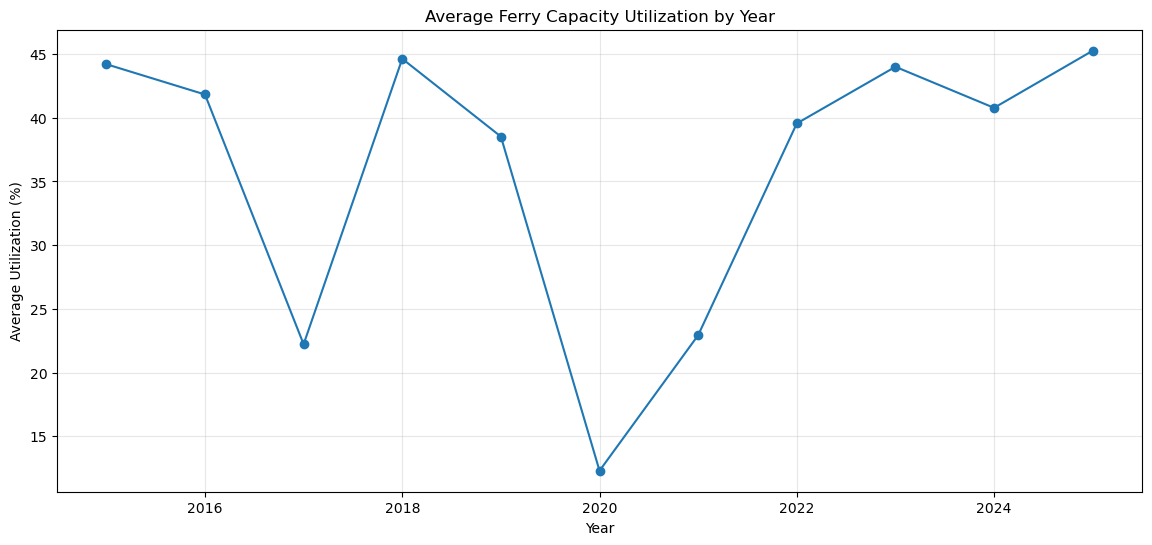

In [43]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_kpis["year"],
    yearly_kpis["avg_utilization"],
    marker="o"
)

plt.title(
    "Average Ferry Capacity Utilization by Year"
)

plt.xlabel("Year")
plt.ylabel("Average Utilization (%)")

plt.grid(alpha=0.3)

plt.show()

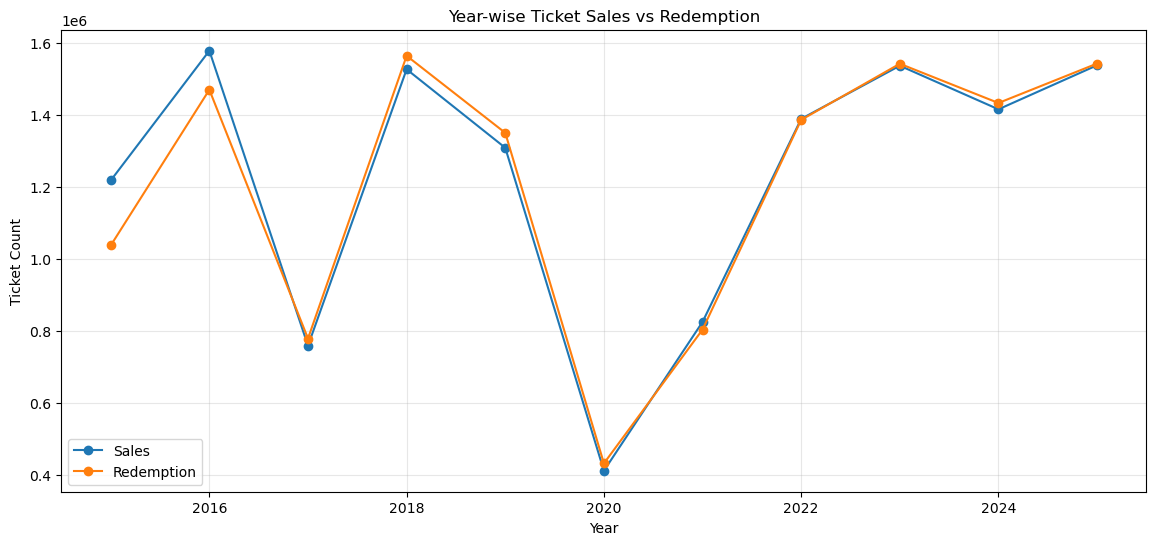

In [44]:
yearly_activity = (
    df.groupby("year")
    .agg({
        "sales_count": "sum",
        "redemption_count": "sum"
    })
    .reset_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    yearly_activity["year"],
    yearly_activity["sales_count"],
    marker="o",
    label="Sales"
)

plt.plot(
    yearly_activity["year"],
    yearly_activity["redemption_count"],
    marker="o",
    label="Redemption"
)

plt.title("Year-wise Ticket Sales vs Redemption")
plt.xlabel("Year")
plt.ylabel("Ticket Count")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [45]:
# ============================================================
# WEEKDAY VS WEEKEND
# ============================================================

weekday_weekend = (
    df.groupby("is_weekend")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        idle_percentage=(
            "idle_capacity_indicator",
            "mean"
        ),
        congestion_percentage=(
            "congestion_indicator",
            "mean"
        )
    )
    .reset_index()
)

weekday_weekend["day_type"] = (
    weekday_weekend["is_weekend"]
    .map({
        0: "Weekday",
        1: "Weekend"
    })
)

weekday_weekend[
    [
        "day_type",
        "avg_utilization",
        "avg_activity",
        "idle_percentage",
        "congestion_percentage"
    ]
]

,day_type,avg_utilization,avg_activity,idle_percentage,congestion_percentage
0,Weekday,29.093,59.555,0.738,0.086
1,Weekend,52.327,102.795,0.703,0.150


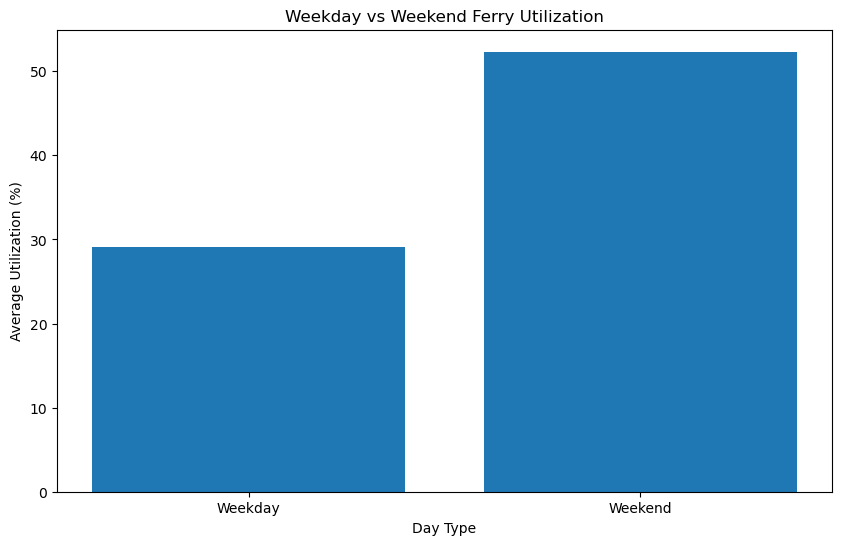

In [46]:
plt.figure(figsize=(10, 6))

plt.bar(
    weekday_weekend["day_type"],
    weekday_weekend["avg_utilization"]
)

plt.title(
    "Weekday vs Weekend Ferry Utilization"
)

plt.xlabel("Day Type")
plt.ylabel("Average Utilization (%)")

plt.show()

In [47]:
# ============================================================
# TIME BAND ANALYSIS
# ============================================================

time_analysis = (
    df.groupby("time_band")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        idle_percentage=(
            "idle_capacity_indicator",
            "mean"
        ),
        congestion_percentage=(
            "congestion_indicator",
            "mean"
        ),
        avg_pressure=(
            "congestion_pressure_index",
            "mean"
        )
    )
    .reset_index()
)

time_order = [
    "Morning",
    "Afternoon",
    "Evening",
    "Night"
]

time_analysis["order"] = (
    time_analysis["time_band"]
    .map({
        x: i for i, x in enumerate(time_order)
    })
)

time_analysis = (
    time_analysis
    .sort_values("order")
    .drop(columns="order")
)

display(time_analysis)

,time_band,avg_utilization,avg_activity,idle_percentage,congestion_percentage,avg_pressure
2,Morning,36.396,72.923,0.734,0.103,51.317
0,Afternoon,86.437,168.941,0.426,0.274,70.131
1,Evening,28.588,59.320,0.663,0.080,55.342
3,Night,3.973,10.617,0.984,0.003,30.485


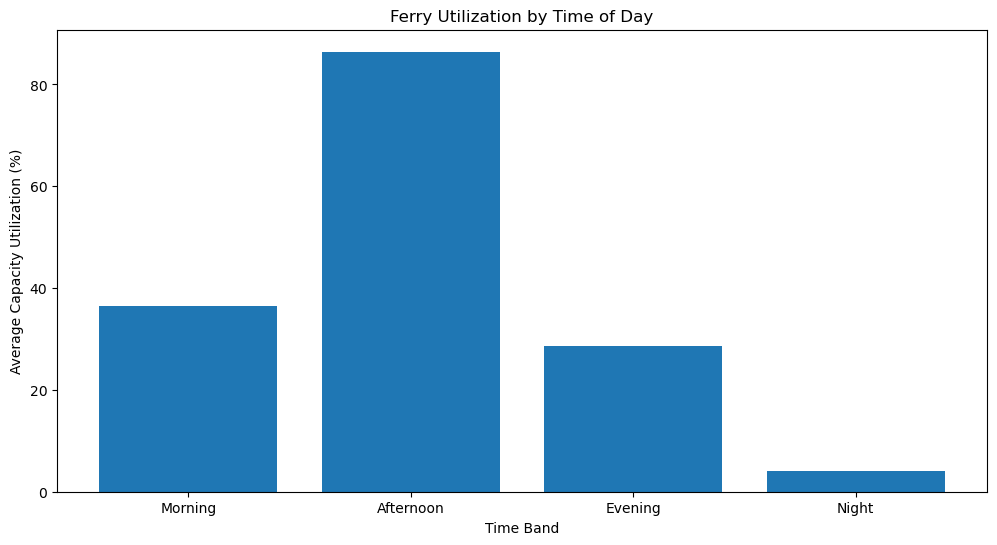

In [48]:
plt.figure(figsize=(12, 6))

plt.bar(
    time_analysis["time_band"],
    time_analysis["avg_utilization"]
)

plt.title(
    "Ferry Utilization by Time of Day"
)

plt.xlabel("Time Band")
plt.ylabel("Average Capacity Utilization (%)")

plt.show()

In [49]:
# ============================================================
# SEASONAL EFFICIENCY
# ============================================================

season_analysis = (
    df.groupby("season")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        idle_percentage=(
            "idle_capacity_indicator",
            "mean"
        ),
        congestion_percentage=(
            "congestion_indicator",
            "mean"
        ),
        avg_pressure=(
            "congestion_pressure_index",
            "mean"
        )
    )
    .reset_index()
)

display(season_analysis)

,season,avg_utilization,avg_activity,idle_percentage,congestion_percentage,avg_pressure
0,Monsoon,82.129,166.689,0.528,0.270,64.136
1,Summer,29.020,59.028,0.731,0.085,49.495
2,Winter/Off-Season,11.699,22.146,0.853,0.015,41.436


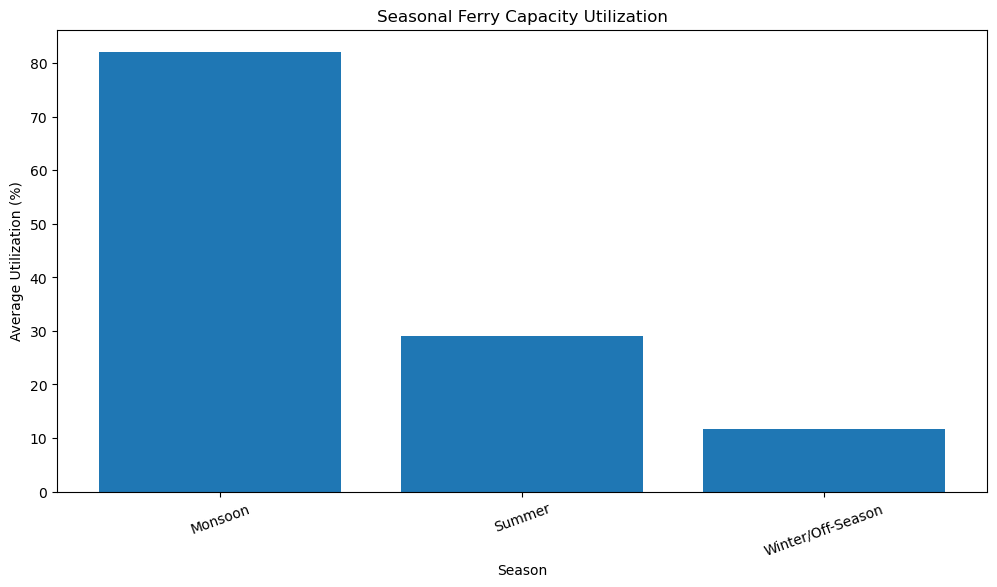

In [50]:
plt.figure(figsize=(12, 6))

plt.bar(
    season_analysis["season"],
    season_analysis["avg_utilization"]
)

plt.title(
    "Seasonal Ferry Capacity Utilization"
)

plt.xlabel("Season")
plt.ylabel("Average Utilization (%)")

plt.xticks(rotation=20)

plt.show()

In [51]:
monthly_analysis = (
    df.groupby("month")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        idle_percentage=(
            "idle_capacity_indicator",
            "mean"
        ),
        congestion_percentage=(
            "congestion_indicator",
            "mean"
        )
    )
    .reset_index()
)

display(monthly_analysis)

#51

,month,avg_utilization,avg_activity,idle_percentage,congestion_percentage
0,1,7.555,14.115,0.929,0.005
1,2,8.310,15.475,0.903,0.004
2,3,9.577,18.166,0.871,0.005
3,4,15.639,31.339,0.783,0.028
4,5,33.203,67.954,0.680,0.100
5,6,55.134,113.377,0.603,0.197
6,7,89.644,184.736,0.530,0.296
7,8,103.383,209.255,0.485,0.339
8,9,52.400,104.054,0.569,0.172
9,10,21.909,42.745,0.693,0.052


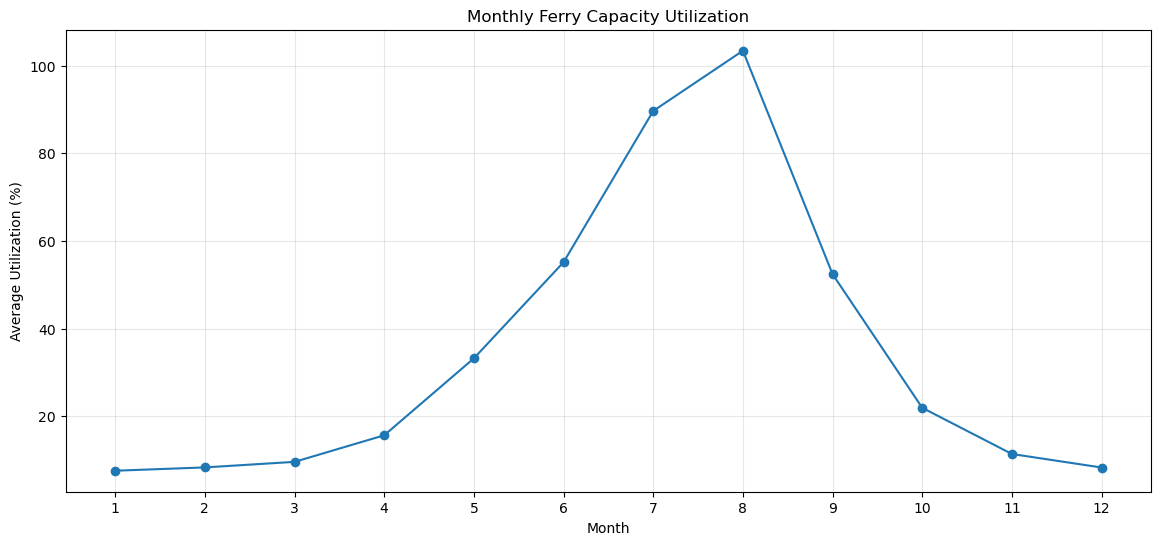

In [52]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["month"],
    monthly_analysis["avg_utilization"],
    marker="o"
)

plt.title(
    "Monthly Ferry Capacity Utilization"
)

plt.xlabel("Month")
plt.ylabel("Average Utilization (%)")

plt.xticks(range(1, 13))

plt.grid(alpha=0.3)

plt.show()

In [53]:
hourly_profile = (
    df.groupby("hour")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        congestion=(
            "congestion_indicator",
            "mean"
        ),
        idle=(
            "idle_capacity_indicator",
            "mean"
        )
    )
    .reset_index()
)

hourly_profile["congestion"] *= 100
hourly_profile["idle"] *= 100

display(hourly_profile)

,hour,avg_utilization,avg_activity,congestion,idle
0,0,2.278,7.974,0.122,99.563
1,1,2.683,6.973,0.219,99.518
2,2,3.227,7.244,0.309,99.087
3,3,3.869,8.231,0.296,98.141
4,4,4.698,9.563,0.277,96.141
5,5,5.781,11.589,0.199,92.874
6,6,9.705,17.908,0.515,85.754
7,7,7.716,17.434,0.720,96.154
8,8,16.775,39.752,2.110,73.321
9,9,44.115,93.551,16.234,64.079


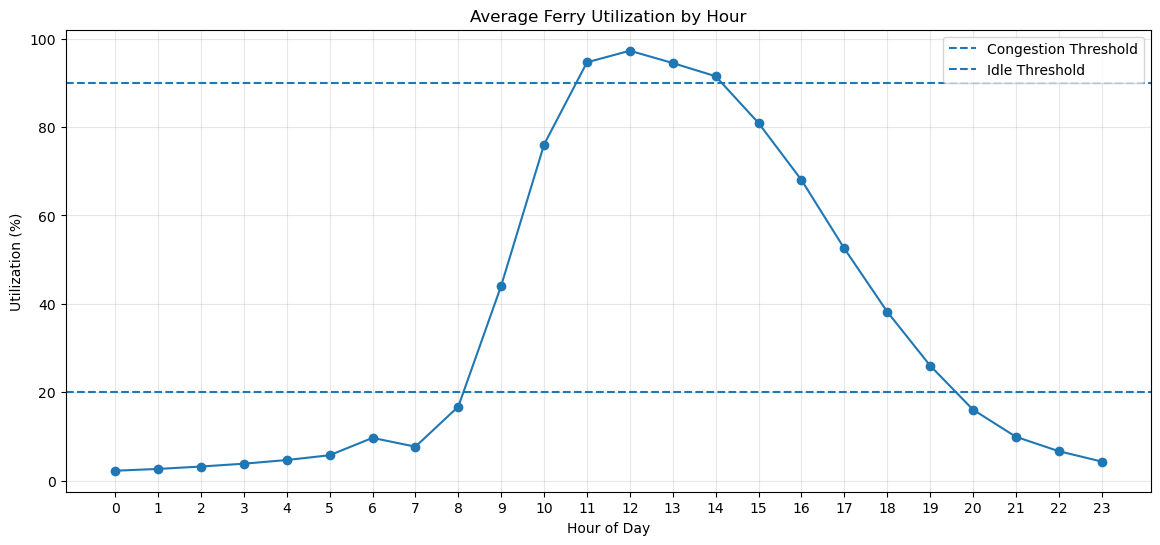

In [54]:
plt.figure(figsize=(14, 6))

plt.plot(
    hourly_profile["hour"],
    hourly_profile["avg_utilization"],
    marker="o"
)

plt.axhline(
    90,
    linestyle="--",
    label="Congestion Threshold"
)

plt.axhline(
    20,
    linestyle="--",
    label="Idle Threshold"
)

plt.title(
    "Average Ferry Utilization by Hour"
)

plt.xlabel("Hour of Day")
plt.ylabel("Utilization (%)")

plt.xticks(range(0, 24))

plt.legend()
plt.grid(alpha=0.3)

plt.show()

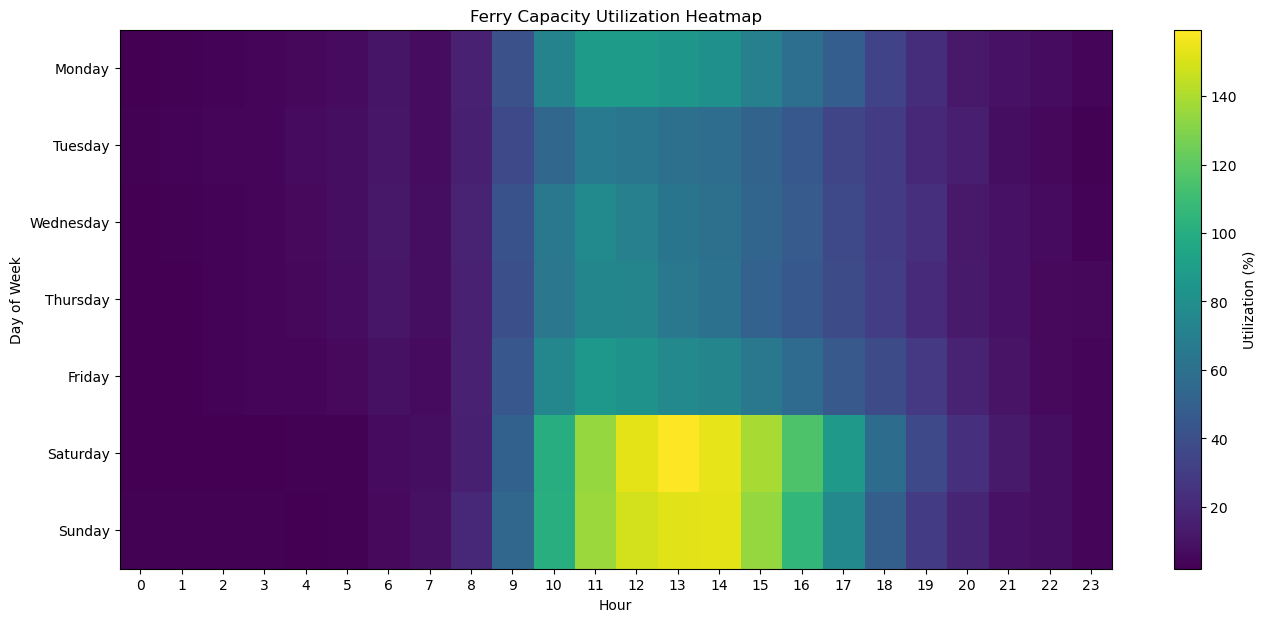

In [55]:
# ============================================================
# CONGESTION / UTILIZATION HEATMAP
# ============================================================

heatmap_data = (
    df.pivot_table(
        index="day_name",
        columns="hour",
        values="capacity_utilization_percentage",
        aggfunc="mean"
    )
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

heatmap_data = heatmap_data.reindex(
    day_order
)

plt.figure(figsize=(16, 7))

plt.imshow(
    heatmap_data,
    aspect="auto"
)

plt.colorbar(
    label="Utilization (%)"
)

plt.title(
    "Ferry Capacity Utilization Heatmap"
)

plt.xlabel("Hour")
plt.ylabel("Day of Week")

plt.xticks(
    range(24),
    range(24)
)

plt.yticks(
    range(7),
    day_order
)

plt.show()

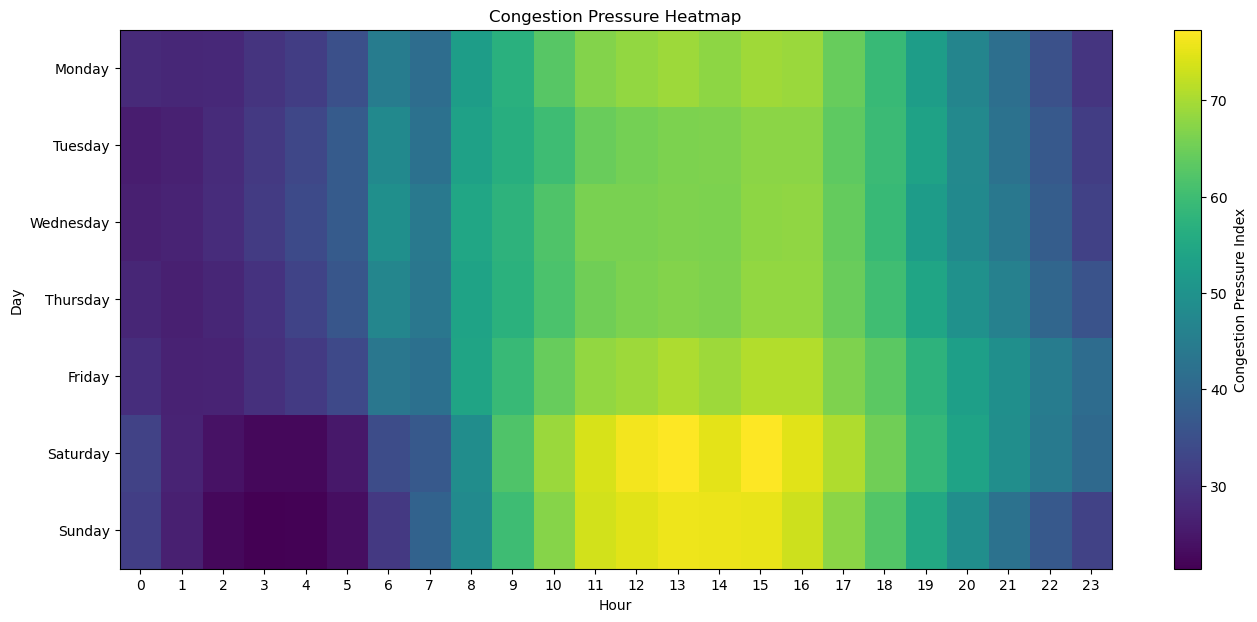

In [56]:
congestion_heatmap = (
    df.pivot_table(
        index="day_name",
        columns="hour",
        values="congestion_pressure_index",
        aggfunc="mean"
    )
)

congestion_heatmap = (
    congestion_heatmap
    .reindex(day_order)
)

plt.figure(figsize=(16, 7))

plt.imshow(
    congestion_heatmap,
    aspect="auto"
)

plt.colorbar(
    label="Congestion Pressure Index"
)

plt.title(
    "Congestion Pressure Heatmap"
)

plt.xlabel("Hour")
plt.ylabel("Day")

plt.xticks(
    range(24),
    range(24)
)

plt.yticks(
    range(7),
    day_order
)

plt.show()

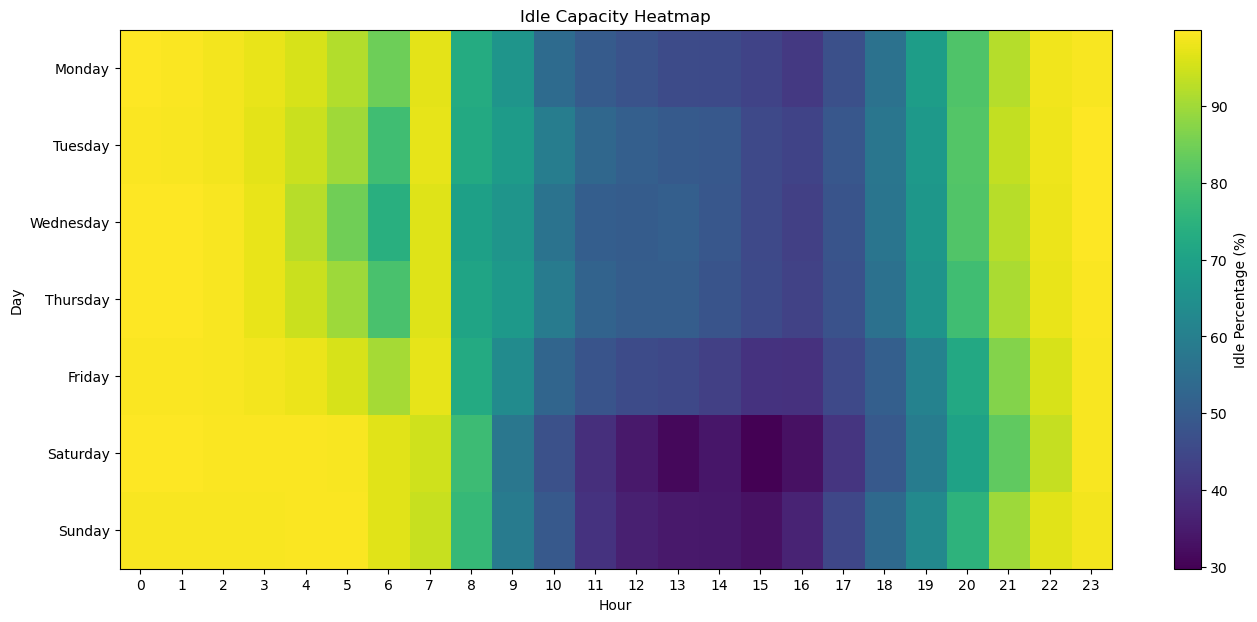

In [57]:
idle_heatmap = (
    df.pivot_table(
        index="day_name",
        columns="hour",
        values="idle_capacity_indicator",
        aggfunc="mean"
    ) * 100
)

idle_heatmap = (
    idle_heatmap
    .reindex(day_order)
)

plt.figure(figsize=(16, 7))

plt.imshow(
    idle_heatmap,
    aspect="auto"
)

plt.colorbar(
    label="Idle Percentage (%)"
)

plt.title(
    "Idle Capacity Heatmap"
)

plt.xlabel("Hour")
plt.ylabel("Day")

plt.xticks(
    range(24),
    range(24)
)

plt.yticks(
    range(7),
    day_order
)

plt.show()

In [58]:
# ============================================================
# TOP CONGESTION WINDOWS
# ============================================================

top_congestion = (
    df[
        df["congestion_indicator"] == 1
    ]
    .sort_values(
        "congestion_pressure_index",
        ascending=False
    )
)

display(
    top_congestion[
        [
            "timestamp",
            "sales_count",
            "redemption_count",
            "total_activity_load",
            "capacity_utilization_percentage",
            "congestion_pressure_index",
            "operational_status"
        ]
    ].head(20)
)

,timestamp,sales_count,redemption_count,total_activity_load,capacity_utilization_percentage,congestion_pressure_index,operational_status
290715,2023-08-15 20:15:00,"7,229.000","7,216.000","14,445.000","7,216.000",100.000,Critical / Over-Utilized
296066,2023-10-10 14:00:00,"5,518.000","5,535.000","11,053.000","5,535.000",100.000,Critical / Over-Utilized
320374,2024-06-19 19:00:00,"5,342.000","5,341.000","10,683.000","5,341.000",99.999,Critical / Over-Utilized
362512,2025-09-01 17:30:00,"5,218.000","5,256.000","10,474.000","5,256.000",99.999,Critical / Over-Utilized
324898,2024-08-05 22:00:00,"4,995.000","4,973.000","9,968.000","4,973.000",99.999,Critical / Over-Utilized
328046,2024-09-07 17:00:00,"4,974.000","4,966.000","9,940.000","4,966.000",99.999,Critical / Over-Utilized
364740,2025-09-24 22:30:00,"4,015.000","4,020.000","8,035.000","4,020.000",99.998,Critical / Over-Utilized
358119,2025-07-17 23:15:00,"3,701.000","3,692.000","7,393.000","3,692.000",99.998,Critical / Over-Utilized
286783,2023-07-05 21:15:00,"3,634.000","3,602.000","7,236.000","3,602.000",99.998,Critical / Over-Utilized
255636,2022-08-15 10:30:00,"3,408.000","3,520.000","6,928.000","3,520.000",99.998,Critical / Over-Utilized


In [59]:
# ============================================================
# TOP IDLE WINDOWS
# ============================================================

top_idle = (
    df[
        df["idle_capacity_indicator"] == 1
    ]
    .sort_values(
        "capacity_utilization_percentage"
    )
)

display(
    top_idle[
        [
            "timestamp",
            "sales_count",
            "redemption_count",
            "total_activity_load",
            "capacity_utilization_percentage",
            "operational_status"
        ]
    ].head(20)
)

,timestamp,sales_count,redemption_count,total_activity_load,capacity_utilization_percentage,operational_status
0,2015-05-01 13:30:00,1.000,0.000,1.000,0.000,Idle / Very Low Utilization
207692,2021-04-03 00:30:00,2.000,0.000,2.000,0.000,Idle / Very Low Utilization
293050,2023-09-09 04:00:00,2.769,0.000,2.769,0.000,Idle / Very Low Utilization
207693,2021-04-03 00:45:00,1.667,0.000,1.667,0.000,Idle / Very Low Utilization
207694,2021-04-03 01:00:00,1.333,0.000,1.333,0.000,Idle / Very Low Utilization
207695,2021-04-03 01:15:00,1.000,0.000,1.000,0.000,Idle / Very Low Utilization
293049,2023-09-09 03:45:00,2.615,0.000,2.615,0.000,Idle / Very Low Utilization
293048,2023-09-09 03:30:00,2.462,0.000,2.462,0.000,Idle / Very Low Utilization
293047,2023-09-09 03:15:00,2.308,0.000,2.308,0.000,Idle / Very Low Utilization
293046,2023-09-09 03:00:00,2.154,0.000,2.154,0.000,Idle / Very Low Utilization


In [60]:
# ============================================================
# RESOURCE INEFFICIENCY PROXY
# ============================================================

df["resource_inefficiency_score"] = (
    (100 - df["capacity_utilization_percentage"])
    * (1 + df["idle_capacity_indicator"])
)

# Normalize to 0–100
min_score = df["resource_inefficiency_score"].min()
max_score = df["resource_inefficiency_score"].max()

df["resource_inefficiency_score"] = (
    (
        df["resource_inefficiency_score"] -
        min_score
    ) /
    (max_score - min_score + 1e-9)
) * 100

display(
    df[
        [
            "timestamp",
            "capacity_utilization_percentage",
            "resource_inefficiency_score"
        ]
    ].sort_values(
        "resource_inefficiency_score",
        ascending=False
    ).head(20)
)

,timestamp,capacity_utilization_percentage,resource_inefficiency_score
0,2015-05-01 13:30:00,0.000,100.000
204046,2021-02-24 01:00:00,0.000,100.000
204044,2021-02-24 00:30:00,0.000,100.000
204043,2021-02-24 00:15:00,0.000,100.000
204042,2021-02-24 00:00:00,0.000,100.000
204041,2021-02-23 23:45:00,0.000,100.000
204040,2021-02-23 23:30:00,0.000,100.000
204039,2021-02-23 23:15:00,0.000,100.000
204038,2021-02-23 23:00:00,0.000,100.000
204037,2021-02-23 22:45:00,0.000,100.000


In [61]:
# ============================================================
# OPERATIONAL VARIABILITY SCORE
# ============================================================

# Coefficient of variation
mean_utilization = (
    df["capacity_utilization_ratio"].mean()
)

std_utilization = (
    df["capacity_utilization_ratio"].std()
)

cv = (
    std_utilization /
    (mean_utilization + 1e-9)
)

# Convert stability into 0–100
# Higher score = more stable
operational_stability_score = (
    100 / (1 + cv)
)

print(
    "Operational Variability (CV):",
    round(cv, 4)
)

print(
    "Operational Stability Score:",
    round(
        operational_stability_score,
        2
    )
)

Operational Variability (CV): 2.519
Operational Stability Score: 28.42


In [62]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Use hourly data for ML instead of millions of 15-minute rows
# This significantly reduces memory and computation time.

ml_features = [
    "sales_count",
    "redemption_count",
    "total_activity_load",
    "redemption_pressure_ratio",
    "capacity_utilization_ratio",
    "congestion_pressure_index",
    "oli_score"
]

# Select only required columns
ml_data = df_hourly[ml_features].copy()

print("Original ML data shape:", ml_data.shape)

# Replace infinite values
ml_data = ml_data.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fill missing values with median
ml_data = ml_data.fillna(
    ml_data.median(numeric_only=True)
)

# Convert to float32 to reduce memory usage
ml_data = ml_data.astype("float32")

print("Missing values after cleaning:")
print(ml_data.isnull().sum())

# Standardize features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(ml_data)

print("\nML preprocessing completed successfully!")
print("ML feature matrix shape:", X_scaled.shape)

Original ML data shape: (93298, 7)
Missing values after cleaning:
sales_count                   0
redemption_count              0
total_activity_load           0
redemption_pressure_ratio     0
capacity_utilization_ratio    0
congestion_pressure_index     0
oli_score                     0
dtype: int64

ML preprocessing completed successfully!
ML feature matrix shape: (93298, 7)


In [64]:
# ============================================================
# CELL 63 — FIND OPTIMAL NUMBER OF CLUSTERS
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Use maximum 10,000 rows for cluster evaluation
# This keeps the notebook fast.

MAX_SAMPLE = 10000

if len(X_scaled) > MAX_SAMPLE:
    np.random.seed(42)
    sample_index = np.random.choice(
        len(X_scaled),
        MAX_SAMPLE,
        replace=False
    )
    X_sample = X_scaled[sample_index]
else:
    X_sample = X_scaled

print("Data available for ML:", X_scaled.shape)
print("Data used for evaluation:", X_sample.shape)

# Test different values of K
K_range = range(2, 6)

inertias = []
silhouette_scores = []

for k in K_range:

    print("Testing K =", k)

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    inertias.append(model.inertia_)

    score = silhouette_score(
        X_sample,
        labels
    )

    silhouette_scores.append(score)

    print(
        "Silhouette Score:",
        round(score, 4)
    )

print("\nCluster evaluation completed!")

Data available for ML: (93298, 7)
Data used for evaluation: (10000, 7)
Testing K = 2
Silhouette Score: 0.7829
Testing K = 3
Silhouette Score: 0.5929
Testing K = 4
Silhouette Score: 0.4913
Testing K = 5
Silhouette Score: 0.4932

Cluster evaluation completed!


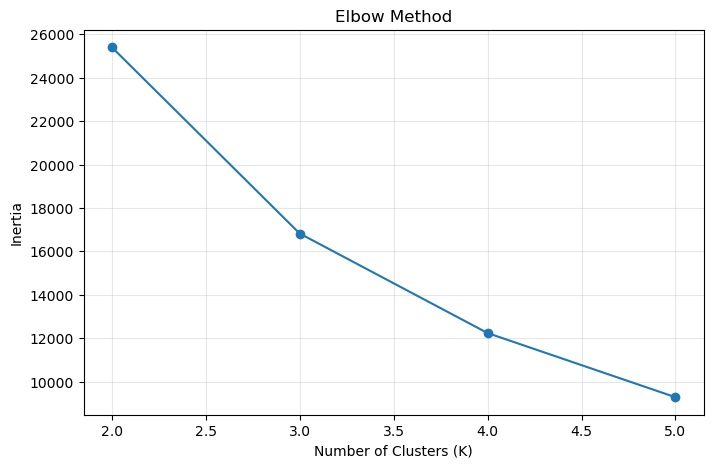

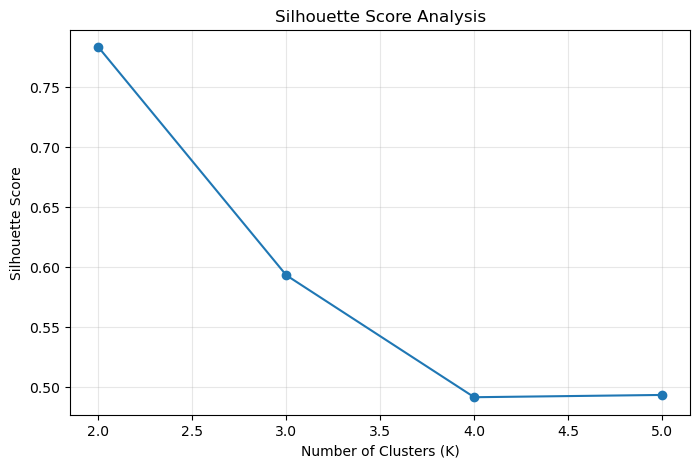

Recommended number of clusters: 2


In [65]:
# ============================================================
# CELL 64 — CLUSTER EVALUATION GRAPHS
# ============================================================

# Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(
    list(K_range),
    inertias,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(alpha=0.3)

plt.show()


# Silhouette Score
plt.figure(figsize=(8, 5))

plt.plot(
    list(K_range),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(alpha=0.3)

plt.show()


# Best K based on silhouette score
best_k = list(K_range)[
    np.argmax(silhouette_scores)
]

print("Recommended number of clusters:", best_k)

In [66]:
# ============================================================
# CELL 65 — FINAL K-MEANS MODEL
# ============================================================

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Train on the complete ML dataset
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to ML data
ml_data["operational_cluster"] = cluster_labels

print("K-Means model trained successfully!")

print("\nCluster Distribution:")
print(
    ml_data["operational_cluster"]
    .value_counts()
    .sort_index()
)

K-Means model trained successfully!

Cluster Distribution:
operational_cluster
0     6492
1    86806
Name: count, dtype: int64


In [67]:
# ============================================================
# CELL 66 — ADD CLUSTER LABELS TO DATASET
# ============================================================

# If ml_data was created from the complete df_hourly
# its index corresponds to df_hourly.

df_hourly_ml = df_hourly.loc[
    ml_data.index
].copy()

df_hourly_ml["operational_cluster"] = (
    ml_data["operational_cluster"]
)

print("Cluster labels added successfully!")

display(
    df_hourly_ml[
        [
            "timestamp",
            "capacity_utilization_percentage",
            "operational_cluster"
        ]
    ].head(10)
)

Cluster labels added successfully!


,timestamp,capacity_utilization_percentage,operational_cluster
0,2015-05-01 13:00:00,0.000,1
1,2015-05-01 14:00:00,0.000,1
2,2015-05-01 15:00:00,0.000,1
3,2015-05-01 16:00:00,0.995,1
4,2015-05-01 17:00:00,0.981,1
5,2015-05-01 18:00:00,0.967,1
6,2015-05-01 19:00:00,0.953,1
7,2015-05-01 20:00:00,0.939,1
8,2015-05-01 21:00:00,0.925,1
9,2015-05-01 22:00:00,0.911,1


In [68]:
cluster_profile = (
    ml_data.groupby("operational_cluster")
    .agg(
        avg_sales=("sales_count", "mean"),
        avg_redemption=("redemption_count", "mean"),
        avg_activity=("total_activity_load", "mean"),
        avg_utilization=("capacity_utilization_ratio", "mean"),
        avg_pressure=("congestion_pressure_index", "mean"),
        idle_percentage=("capacity_utilization_ratio", 
                         lambda x: (x < 0.20).mean() * 100),
        congestion_percentage=("capacity_utilization_ratio",
                               lambda x: (x >= 0.90).mean() * 100),
        observations=("operational_cluster", "count")
    )
    .reset_index()
)

display(cluster_profile)

,operational_cluster,avg_sales,avg_redemption,avg_activity,avg_utilization,avg_pressure,idle_percentage,congestion_percentage,observations
0,0,"1,088.177","1,166.821","2,254.998",2.917,95.939,0.801,98.737,6492
1,1,74.176,66.384,140.560,0.166,46.564,78.914,3.797,86806


In [69]:
high_cluster = cluster_profile.loc[
    cluster_profile["avg_utilization"].idxmax(),
    "operational_cluster"
]

low_cluster = cluster_profile.loc[
    cluster_profile["avg_utilization"].idxmin(),
    "operational_cluster"
]

cluster_profile["operational_state"] = "Normal"

cluster_profile.loc[
    cluster_profile["operational_cluster"] == high_cluster,
    "operational_state"
] = "High Pressure"

cluster_profile.loc[
    cluster_profile["operational_cluster"] == low_cluster,
    "operational_state"
] = "Low Utilization"

display(cluster_profile)

,operational_cluster,avg_sales,avg_redemption,avg_activity,avg_utilization,avg_pressure,idle_percentage,congestion_percentage,observations,operational_state
0,0,"1,088.177","1,166.821","2,254.998",2.917,95.939,0.801,98.737,6492,High Pressure
1,1,74.176,66.384,140.560,0.166,46.564,78.914,3.797,86806,Low Utilization


In [70]:
state_mapping = dict(
    zip(
        cluster_profile["operational_cluster"],
        cluster_profile["operational_state"]
    )
)

df_hourly_ml["operational_state"] = (
    df_hourly_ml["operational_cluster"]
    .map(state_mapping)
)

display(
    df_hourly_ml[
        [
            "timestamp",
            "capacity_utilization_percentage",
            "operational_cluster",
            "operational_state"
        ]
    ].head(10)
)

,timestamp,capacity_utilization_percentage,operational_cluster,operational_state
0,2015-05-01 13:00:00,0.000,1,Low Utilization
1,2015-05-01 14:00:00,0.000,1,Low Utilization
2,2015-05-01 15:00:00,0.000,1,Low Utilization
3,2015-05-01 16:00:00,0.995,1,Low Utilization
4,2015-05-01 17:00:00,0.981,1,Low Utilization
5,2015-05-01 18:00:00,0.967,1,Low Utilization
6,2015-05-01 19:00:00,0.953,1,Low Utilization
7,2015-05-01 20:00:00,0.939,1,Low Utilization
8,2015-05-01 21:00:00,0.925,1,Low Utilization
9,2015-05-01 22:00:00,0.911,1,Low Utilization


In [71]:
state_distribution = (
    df_hourly_ml["operational_state"]
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)

state_distribution.columns = [
    "Operational State",
    "Percentage"
]

display(state_distribution)

,Operational State,Percentage
0,Low Utilization,93.042
1,High Pressure,6.958


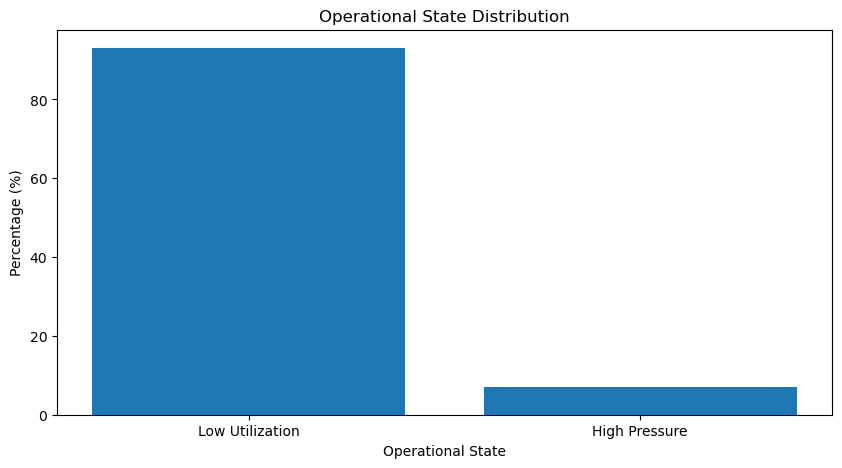

In [72]:
plt.figure(figsize=(10, 5))

plt.bar(
    state_distribution["Operational State"],
    state_distribution["Percentage"]
)

plt.title("Operational State Distribution")
plt.xlabel("Operational State")
plt.ylabel("Percentage (%)")

plt.show()

In [73]:
yearly_ml = (
    df_hourly_ml
    .assign(year=df_hourly_ml["timestamp"].dt.year)
    .groupby("year")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        high_pressure_percentage=(
            "operational_state",
            lambda x: (x == "High Pressure").mean() * 100
        ),
        low_utilization_percentage=(
            "operational_state",
            lambda x: (x == "Low Utilization").mean() * 100
        )
    )
    .reset_index()
)

display(yearly_ml)

,year,avg_utilization,avg_activity,high_pressure_percentage,low_utilization_percentage
0,2015,44.196,384.314,9.988,90.012
1,2016,41.823,346.915,8.777,91.223
2,2017,22.229,175.555,3.482,96.518
3,2018,44.626,352.733,8.801,91.199
4,2019,38.522,303.444,7.180,92.820
5,2020,12.304,96.121,0.546,99.454
6,2021,22.937,185.929,3.676,96.324
7,2022,39.551,316.724,7.820,92.180
8,2023,43.996,351.348,9.235,90.765
9,2024,40.776,324.215,8.219,91.781


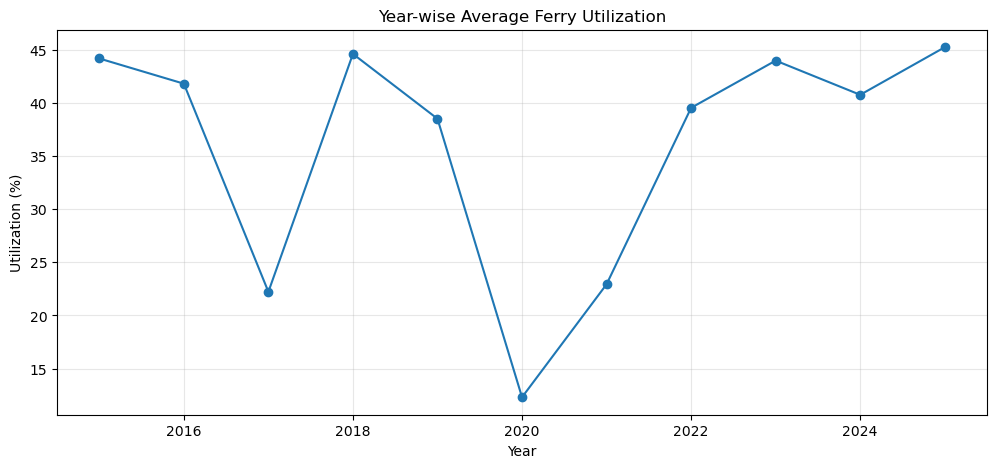

In [74]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_ml["year"],
    yearly_ml["avg_utilization"],
    marker="o"
)

plt.title("Year-wise Average Ferry Utilization")
plt.xlabel("Year")
plt.ylabel("Utilization (%)")
plt.grid(alpha=0.3)

plt.show()

In [75]:
season_ml = (
    df.groupby("season")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        avg_activity=(
            "total_activity_load",
            "mean"
        ),
        idle_percentage=(
            "idle_capacity_indicator",
            "mean"
        ),
        congestion_percentage=(
            "congestion_indicator",
            "mean"
        )
    )
    .reset_index()
)

season_ml["idle_percentage"] *= 100
season_ml["congestion_percentage"] *= 100

display(season_ml)

,season,avg_utilization,avg_activity,idle_percentage,congestion_percentage
0,Monsoon,82.129,166.689,52.775,27.001
1,Summer,29.020,59.028,73.063,8.505
2,Winter/Off-Season,11.699,22.146,85.262,1.518


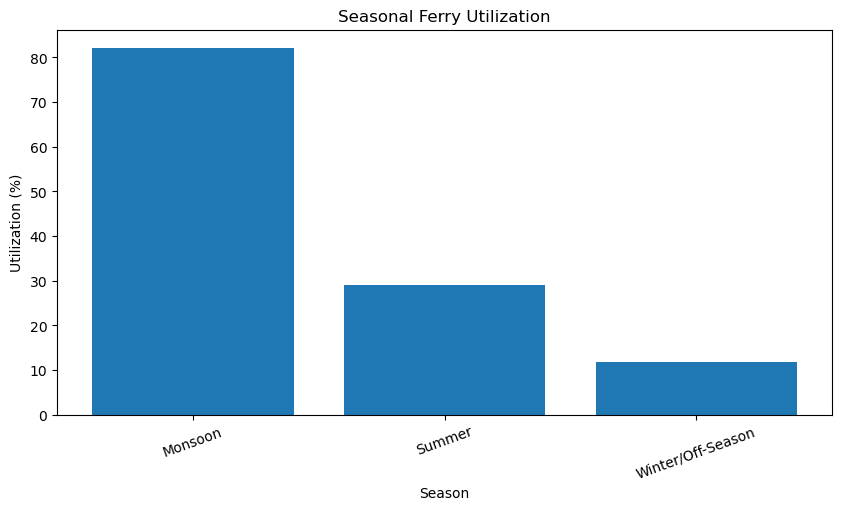

In [76]:
plt.figure(figsize=(10, 5))

plt.bar(
    season_ml["season"],
    season_ml["avg_utilization"]
)

plt.title("Seasonal Ferry Utilization")
plt.xlabel("Season")
plt.ylabel("Utilization (%)")

plt.xticks(rotation=20)

plt.show()

In [77]:
time_ml = (
    df.groupby("time_band")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        idle_percentage=(
            "idle_capacity_indicator",
            "mean"
        ),
        congestion_percentage=(
            "congestion_indicator",
            "mean"
        )
    )
    .reset_index()
)

time_ml["idle_percentage"] *= 100
time_ml["congestion_percentage"] *= 100

display(time_ml)

,time_band,avg_utilization,idle_percentage,congestion_percentage
0,Afternoon,86.437,42.595,27.388
1,Evening,28.588,66.319,8.016
2,Morning,36.396,73.396,10.276
3,Night,3.973,98.367,0.276


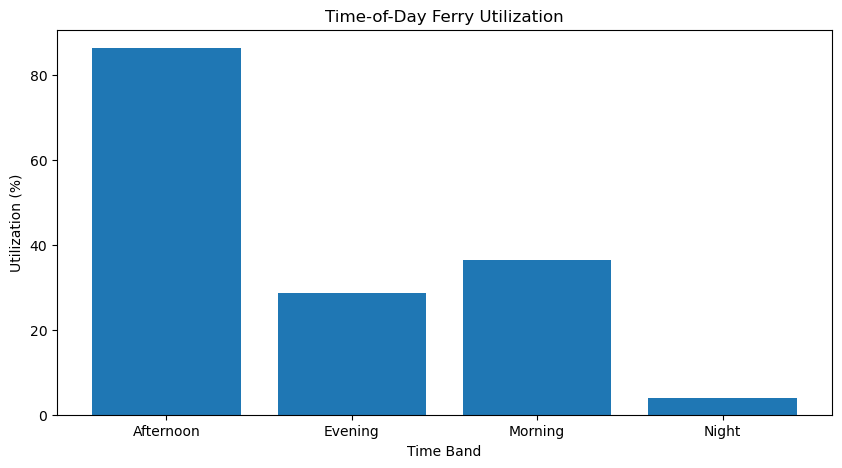

In [78]:
plt.figure(figsize=(10, 5))

plt.bar(
    time_ml["time_band"],
    time_ml["avg_utilization"]
)

plt.title("Time-of-Day Ferry Utilization")
plt.xlabel("Time Band")
plt.ylabel("Utilization (%)")

plt.show()

In [79]:
top_congestion = (
    df.sort_values(
        "congestion_pressure_index",
        ascending=False
    )
    [
        [
            "timestamp",
            "sales_count",
            "redemption_count",
            "total_activity_load",
            "capacity_utilization_percentage",
            "congestion_pressure_index",
            "operational_status"
        ]
    ]
    .head(20)
)

display(top_congestion)

,timestamp,sales_count,redemption_count,total_activity_load,capacity_utilization_percentage,congestion_pressure_index,operational_status
290715,2023-08-15 20:15:00,"7,229.000","7,216.000","14,445.000","7,216.000",100.000,Critical / Over-Utilized
296066,2023-10-10 14:00:00,"5,518.000","5,535.000","11,053.000","5,535.000",100.000,Critical / Over-Utilized
320374,2024-06-19 19:00:00,"5,342.000","5,341.000","10,683.000","5,341.000",99.999,Critical / Over-Utilized
362512,2025-09-01 17:30:00,"5,218.000","5,256.000","10,474.000","5,256.000",99.999,Critical / Over-Utilized
324898,2024-08-05 22:00:00,"4,995.000","4,973.000","9,968.000","4,973.000",99.999,Critical / Over-Utilized
328046,2024-09-07 17:00:00,"4,974.000","4,966.000","9,940.000","4,966.000",99.999,Critical / Over-Utilized
364740,2025-09-24 22:30:00,"4,015.000","4,020.000","8,035.000","4,020.000",99.998,Critical / Over-Utilized
358119,2025-07-17 23:15:00,"3,701.000","3,692.000","7,393.000","3,692.000",99.998,Critical / Over-Utilized
286783,2023-07-05 21:15:00,"3,634.000","3,602.000","7,236.000","3,602.000",99.998,Critical / Over-Utilized
255636,2022-08-15 10:30:00,"3,408.000","3,520.000","6,928.000","3,520.000",99.998,Critical / Over-Utilized


In [80]:
top_idle = (
    df.sort_values(
        "capacity_utilization_percentage"
    )
    [
        [
            "timestamp",
            "sales_count",
            "redemption_count",
            "total_activity_load",
            "capacity_utilization_percentage",
            "operational_status"
        ]
    ]
    .head(20)
)

display(top_idle)

,timestamp,sales_count,redemption_count,total_activity_load,capacity_utilization_percentage,operational_status
0,2015-05-01 13:30:00,1.000,0.000,1.000,0.000,Idle / Very Low Utilization
204044,2021-02-24 00:30:00,1.400,0.000,1.400,0.000,Idle / Very Low Utilization
204043,2021-02-24 00:15:00,1.500,0.000,1.500,0.000,Idle / Very Low Utilization
204042,2021-02-24 00:00:00,1.600,0.000,1.600,0.000,Idle / Very Low Utilization
204041,2021-02-23 23:45:00,1.700,0.000,1.700,0.000,Idle / Very Low Utilization
204040,2021-02-23 23:30:00,1.800,0.000,1.800,0.000,Idle / Very Low Utilization
204039,2021-02-23 23:15:00,1.900,0.000,1.900,0.000,Idle / Very Low Utilization
204038,2021-02-23 23:00:00,2.000,0.000,2.000,0.000,Idle / Very Low Utilization
204037,2021-02-23 22:45:00,2.000,0.000,2.000,0.000,Idle / Very Low Utilization
204036,2021-02-23 22:30:00,2.000,0.000,2.000,0.000,Idle / Very Low Utilization


In [81]:
kpi_summary = {
    "Average Capacity Utilization (%)": df["capacity_utilization_percentage"].mean(),
    "Peak Capacity Utilization (%)": df["capacity_utilization_percentage"].max(),
    "Idle Capacity (%)": df["idle_capacity_indicator"].mean() * 100,
    "Congestion Period (%)": df["congestion_indicator"].mean() * 100,
    "Average Activity Load": df["total_activity_load"].mean(),
    "Maximum Activity Load": df["total_activity_load"].max(),
    "Operational Variability (%)": (
        df["capacity_utilization_percentage"].std() /
        df["capacity_utilization_percentage"].mean()
    ) * 100
}

kpi_df = pd.DataFrame(
    list(kpi_summary.items()),
    columns=["KPI", "Value"]
)

display(kpi_df)

,KPI,Value
0,Average Capacity Utilization (%),35.739
1,Peak Capacity Utilization (%),"7,216.000"
2,Idle Capacity (%),72.787
3,Congestion Period (%),10.454
4,Average Activity Load,71.923
5,Maximum Activity Load,"14,445.000"
6,Operational Variability (%),251.897


In [82]:
high_pressure = df["congestion_indicator"].astype(int)

groups = (
    high_pressure.ne(high_pressure.shift())
    .cumsum()
)

strain_periods = (
    df[high_pressure == 1]
    .groupby(groups[high_pressure == 1])
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        intervals=("timestamp", "count")
    )
)

strain_periods["duration_hours"] = (
    strain_periods["intervals"] * 0.25
)

peak_strain = strain_periods.sort_values(
    "duration_hours",
    ascending=False
).head(10)

display(peak_strain)

,start,end,intervals,duration_hours
congestion_indicator,,,,
2932,2018-07-01 07:30:00,2018-07-01 21:30:00,57,14.250
2852,2018-06-16 06:30:00,2018-06-16 19:30:00,53,13.250
12222,2025-07-01 08:45:00,2025-07-01 21:30:00,52,13.000
1292,2016-06-18 06:15:00,2016-06-18 19:00:00,52,13.000
9024,2023-06-17 06:15:00,2023-06-17 19:00:00,52,13.000
12290,2025-07-12 08:45:00,2025-07-12 21:00:00,50,12.500
2856,2018-06-17 07:00:00,2018-06-17 19:00:00,49,12.250
10600,2024-07-01 08:30:00,2024-07-01 20:30:00,49,12.250
1474,2016-07-23 08:00:00,2016-07-23 20:00:00,49,12.250


In [83]:
peak_idle = pd.DataFrame({
    "Condition": [
        "Peak / Congestion",
        "Idle / Under-utilized",
        "Normal"
    ],
    "Percentage": [
        (df["congestion_indicator"].mean() * 100),
        (df["idle_capacity_indicator"].mean() * 100),
        (
            (1
             - df["congestion_indicator"].mean()
             - df["idle_capacity_indicator"].mean()
            ) * 100
        )
    ]
})

display(peak_idle)

,Condition,Percentage
0,Peak / Congestion,10.454
1,Idle / Under-utilized,72.787
2,Normal,16.760


In [84]:
variability = (
    df.groupby(df["timestamp"].dt.year)
    ["capacity_utilization_percentage"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

variability["variability_score"] = (
    variability["std"] /
    variability["mean"]
) * 100

display(variability)

,timestamp,mean,std,min,max,variability_score
0,2015,44.200,105.228,0.000,953.000,238.075
1,2016,41.823,101.539,0.000,"1,032.000",242.780
2,2017,22.229,59.599,0.000,"1,620.000",268.119
3,2018,44.626,105.133,0.000,"2,532.000",235.588
4,2019,38.522,89.335,0.000,"2,615.000",231.907
5,2020,12.304,26.894,0.000,339.000,218.581
6,2021,22.937,59.992,0.000,"2,323.000",261.548
7,2022,39.551,94.875,0.000,"3,520.000",239.878
8,2023,43.996,107.774,0.000,"7,216.000",244.961
9,2024,40.776,97.804,0.000,"5,341.000",239.855


In [85]:
low_utilization = df[
    df["capacity_utilization_percentage"] <
    df["capacity_utilization_percentage"].quantile(0.25)
].copy()

low_utilization["hour"] = (
    low_utilization["timestamp"].dt.hour
)

cost_windows = (
    low_utilization
    .groupby("hour")
    .agg(
        avg_utilization=(
            "capacity_utilization_percentage",
            "mean"
        ),
        activity_load=(
            "total_activity_load",
            "mean"
        ),
        observations=("timestamp", "count")
    )
    .sort_values("avg_utilization")
    .reset_index()
)

display(cost_windows.head(10))

,hour,avg_utilization,activity_load,observations
0,2,0.146,3.436,9563
1,1,0.149,4.529,10006
2,3,0.155,3.176,9040
3,4,0.164,2.882,8508
4,5,0.169,2.956,7642
5,0,0.176,7.182,10023
6,6,0.337,3.295,4138
7,23,0.427,9.412,6101
8,22,0.549,9.989,4748
9,16,0.618,27.956,667


In [86]:
avg_util = df["capacity_utilization_percentage"].mean()
idle_pct = df["idle_capacity_indicator"].mean() * 100
congestion_pct = df["congestion_indicator"].mean() * 100

recommendations = []

if congestion_pct > 10:
    recommendations.append(
        "Increase ferry deployment during recurring congestion windows."
    )

if idle_pct > 20:
    recommendations.append(
        "Reduce or reschedule ferry deployment during sustained low-utilization periods."
    )

if variability["variability_score"].mean() > 30:
    recommendations.append(
        "Use flexible scheduling because operational demand shows high variability."
    )

recommendations.append(
    "Use seasonal utilization patterns for long-term fleet and crew planning."
)

recommendations.append(
    "Prioritize peak-period capacity while avoiding unnecessary off-peak deployment."
)

recommendations.append(
    "Monitor operational clusters continuously to detect emerging congestion and idle periods."
)

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

1. Increase ferry deployment during recurring congestion windows.
2. Reduce or reschedule ferry deployment during sustained low-utilization periods.
3. Use flexible scheduling because operational demand shows high variability.
4. Use seasonal utilization patterns for long-term fleet and crew planning.
5. Prioritize peak-period capacity while avoiding unnecessary off-peak deployment.
6. Monitor operational clusters continuously to detect emerging congestion and idle periods.


In [87]:
print("FERRY OPERATIONAL ANALYTICS — EXECUTIVE SUMMARY")
print("=" * 60)

print(
    f"Average capacity utilization: {avg_util:.2f}%"
)

print(
    f"Congestion-prone intervals: {congestion_pct:.2f}%"
)

print(
    f"Idle-capacity intervals: {idle_pct:.2f}%"
)

print(
    f"Average operational variability: "
    f"{variability['variability_score'].mean():.2f}%"
)

print(
    f"Peak activity load: "
    f"{df['total_activity_load'].max():.0f}"
)

print("\nKey Finding:")
print(
    "The analysis identifies temporal, seasonal and operational "
    "patterns that can support evidence-based ferry deployment."
)

print("\nPrimary Recommendation:")
print(
    "Align ferry capacity and operational resources with recurring "
    "peak-pressure and low-utilization windows."
)

FERRY OPERATIONAL ANALYTICS — EXECUTIVE SUMMARY
Average capacity utilization: 35.74%
Congestion-prone intervals: 10.45%
Idle-capacity intervals: 72.79%
Average operational variability: 240.67%
Peak activity load: 14445

Key Finding:
The analysis identifies temporal, seasonal and operational patterns that can support evidence-based ferry deployment.

Primary Recommendation:
Align ferry capacity and operational resources with recurring peak-pressure and low-utilization windows.


In [88]:
output_file = "ferry_operational_analysis.csv"

df_hourly_ml.to_csv(
    output_file,
    index=False
)

print("Final analytical dataset saved:", output_file)

Final analytical dataset saved: ferry_operational_analysis.csv
